# 2026-11-12 멀티미디어 정보처리

## 영역 처리

- 블러링, 샤프닝
- 1차, 2차 미분 및 윤곽선 검출

In [1]:
# 공통부분이기 때문에 실습을 새로운 notebook에서 할때마다 복사해서 실행
import sys
sys.path.append('../multi_info/common') # 모듈이 존재하는 path를 추가
import cvnb
import cv2
import numpy as np
import matplotlib.pyplot as plt

[[0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]]


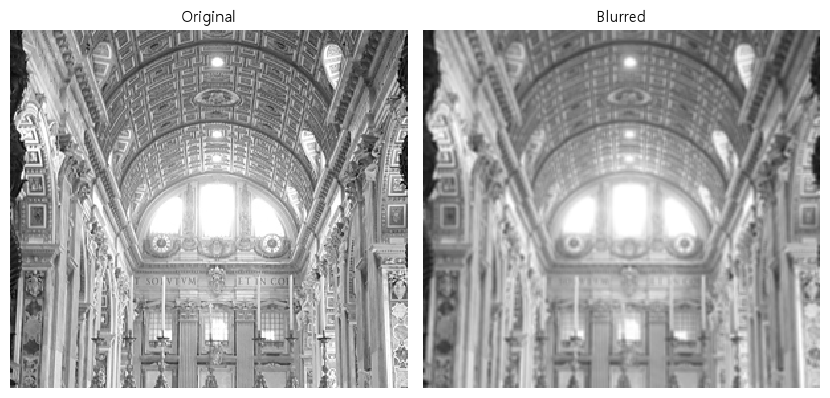

In [2]:
image = cv2.imread("../multi_info/images/filter_blur.jpg", cv2.IMREAD_GRAYSCALE)
if image is None: raise Exception("영상 파일 읽기 오류")

data = [1/9]*9
mask = np.array(data, np.float32).reshape(3,3)
print(mask)
cv2.imshow("Original", image)
blur = cv2.filter2D(image, -1, mask)
cv2.imshow("Blurred", blur)

[[0.16666667 0.16666667 0.16666667]
 [0.16666667 0.16666667 0.16666667]
 [0.16666667 0.16666667 0.16666667]]


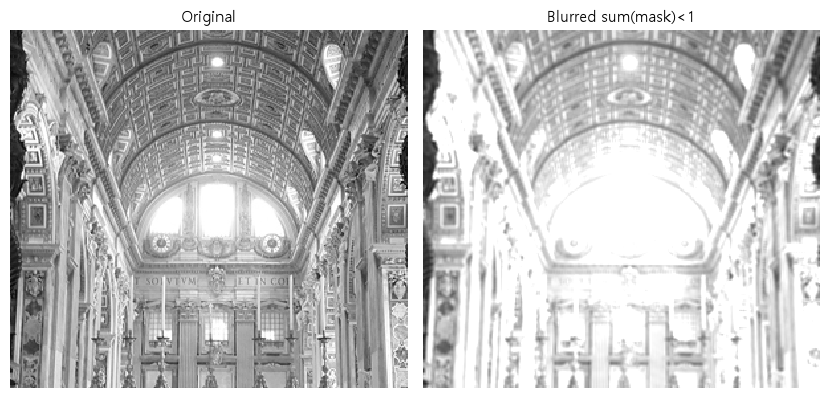

In [3]:
data = [1/6]*9
mask = np.array(data, np.float32).reshape(3,3)
print(mask)
cv2.imshow("Original", image)
blur = cv2.filter2D(image, -1, mask)
cv2.imshow("Blurred sum(mask)<1", blur)

[[0.06666667 0.06666667 0.06666667]
 [0.06666667 0.06666667 0.06666667]
 [0.06666667 0.06666667 0.06666667]] 0.6


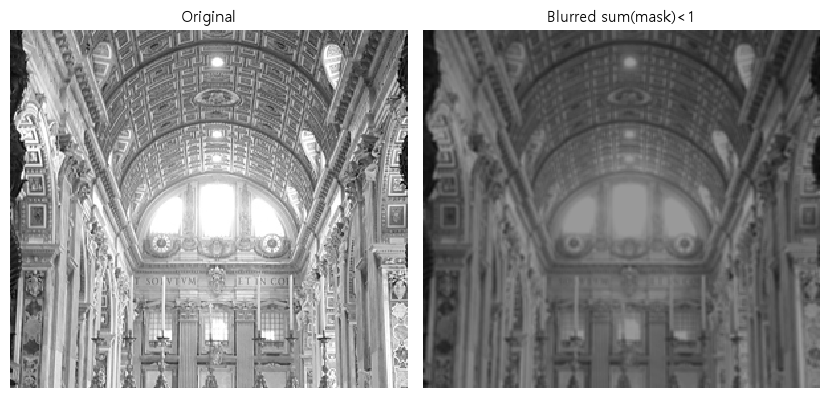

In [4]:
data = [1/15]*9
mask = np.array(data, np.float32).reshape(3,3)
print(mask, sum(data))
cv2.imshow("Original", image)
blur = cv2.filter2D(image, -1, mask)
cv2.imshow("Blurred sum(mask)<1", blur)

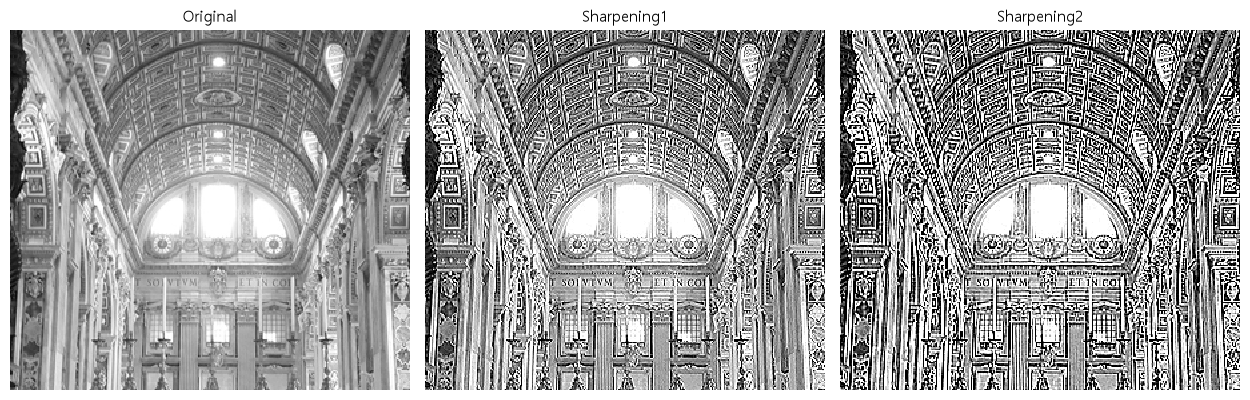

In [5]:
# sharpening: 주위의 화소의 값의 차이를 도드라지게 함. (차이를 크게함)
data = [[0,-1, 0], [-1, 5, -1], [0, -1, 0]]
mask = np.array(data, np.float32).reshape(3,3)
cv2.imshow("Original", image)
sharpen1 = cv2.filter2D(image, -1, mask)
cv2.imshow("Sharpening1", sharpen1)

mask2 = np.array([[-1, -1, -1],[-1, 9, -1],[-1, -1, -1]], np.float32).reshape(3,3)
sharpen2 = cv2.filter2D(image, -1, mask2)
cv2.imshow("Sharpening2", sharpen2)

## 1차 미분에 의한 윤곽선 검출

- 로버츠 에지 검출

[2 1 3 0 3 3 0 0 1 1] [2 1 2 0 3 3 0 0 0 1] [0 0 3 0 1 2 0 0 1 0]


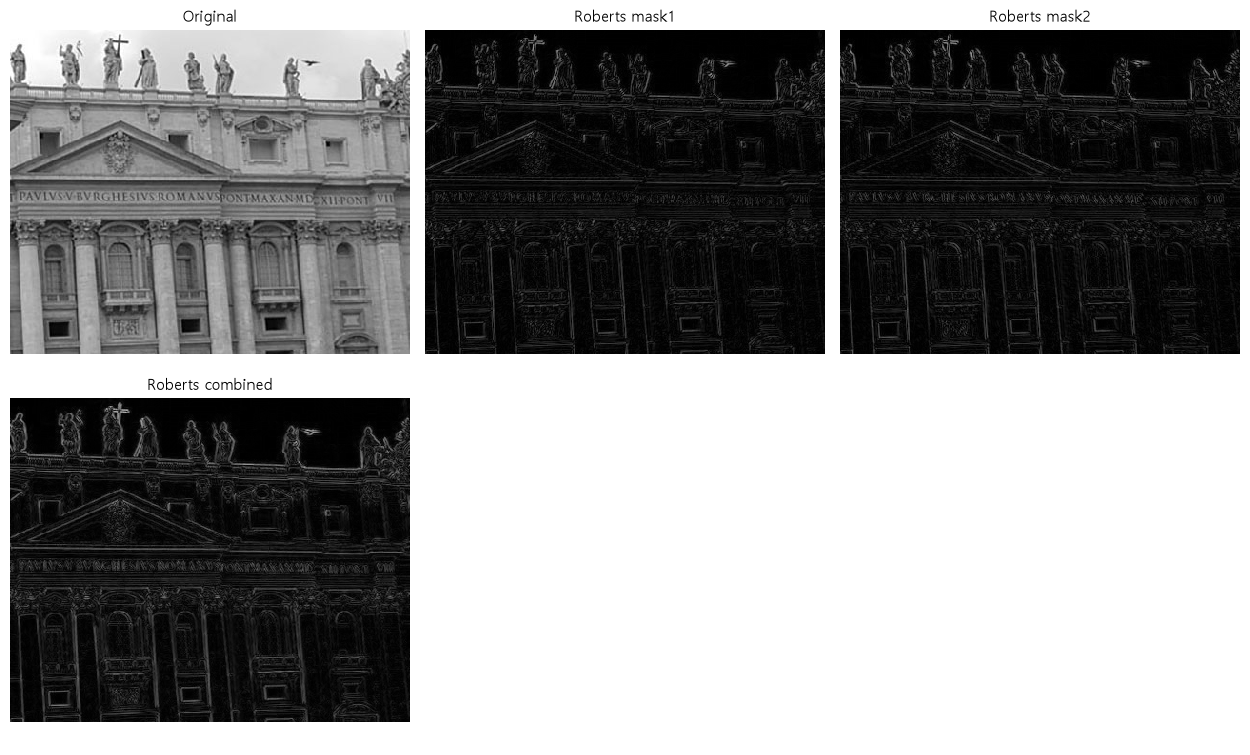

In [9]:
image = cv2.imread("../multi_info/images/edge.jpg", cv2.IMREAD_GRAYSCALE)
if image is None: raise Exception("영상 파일 읽기 오류")

mask1 = np.array([-1, 0, 0, 0, 1, 0, 0, 0, 0], np.float32).reshape(3,3)
mask2 = np.array([0, 0, -1, 0, 1, 0, 0, 0, 0], np.float32).reshape(3,3)
rob1 = cv2.filter2D(image, cv2.CV_32F, mask1)
rob2 = cv2.filter2D(image, cv2.CV_32F, mask2)

rob = cv2.magnitude(rob1, rob2)
rob = np.clip(rob, 0, 255).astype(np.uint8)
rob1_show = cv2.convertScaleAbs(rob1)
rob2_show = cv2.convertScaleAbs(rob2)

print(rob[10, 10:20], rob1_show[10, 10:20], rob2_show[10, 10:20])
cv2.imshow("Original", image)
cv2.imshow("Roberts mask1", rob1_show)
cv2.imshow("Roberts mask2", rob2_show)
cv2.imshow("Roberts combined", rob)

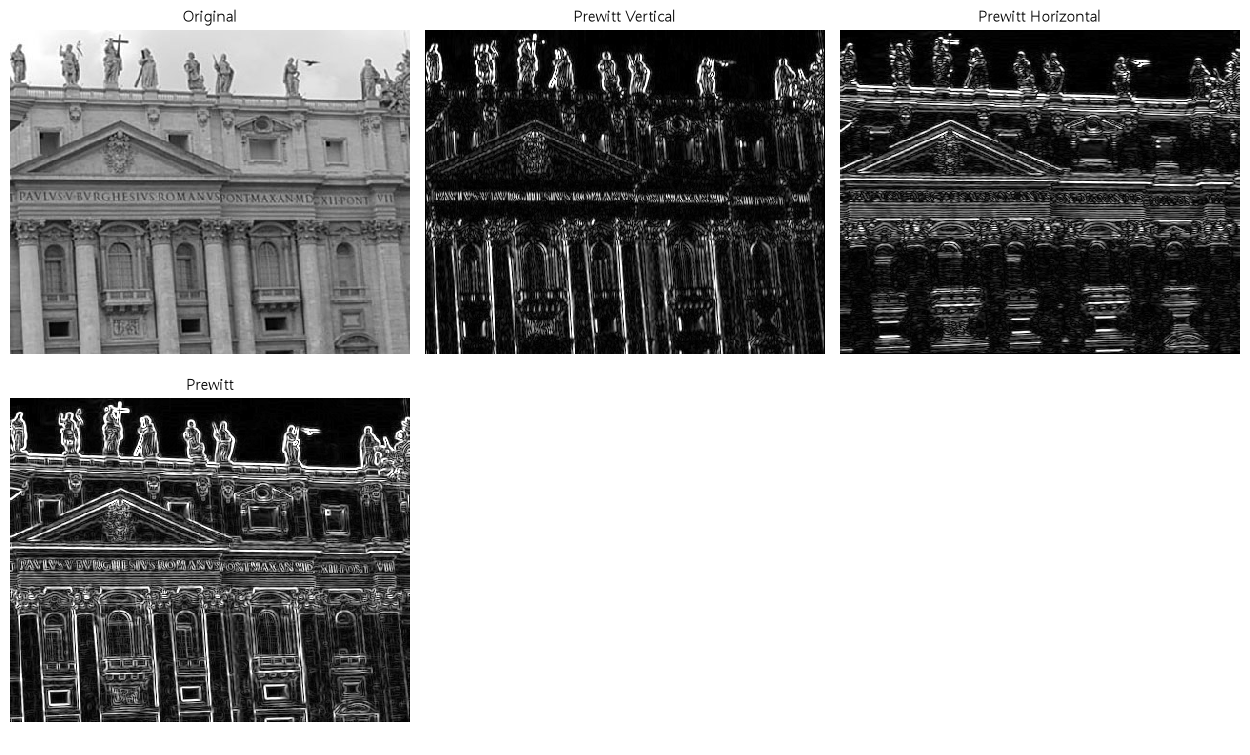

In [10]:
# prewitt 마스크
image = cv2.imread("../multi_info/images/edge.jpg", cv2.IMREAD_GRAYSCALE)
if image is None: raise Exception("영상 파일 읽기 오류")

v_mask = np.array([-1, 0, 1, -1, 0, 1, -1, 0, 1], np.float32).reshape(3,3)
h_mask = np.array([-1, -1, -1, 0, 0, 0, 1, 1, 1], np.float32).reshape(3,3)
prew_v = cv2.filter2D(image, cv2.CV_32F, v_mask)
prew_h = cv2.filter2D(image, cv2.CV_32F, h_mask)

prewitt = cv2.magnitude(prew_v, prew_h)
prewitt = np.clip(prewitt, 0, 255).astype(np.uint8)
prew_v_show = cv2.convertScaleAbs(prew_v)
prew_h_show = cv2.convertScaleAbs(prew_h)

cv2.imshow("Original", image)
cv2.imshow("Prewitt Vertical", prew_v_show)
cv2.imshow("Prewitt Horizontal", prew_h_show)
cv2.imshow("Prewitt", prewitt)

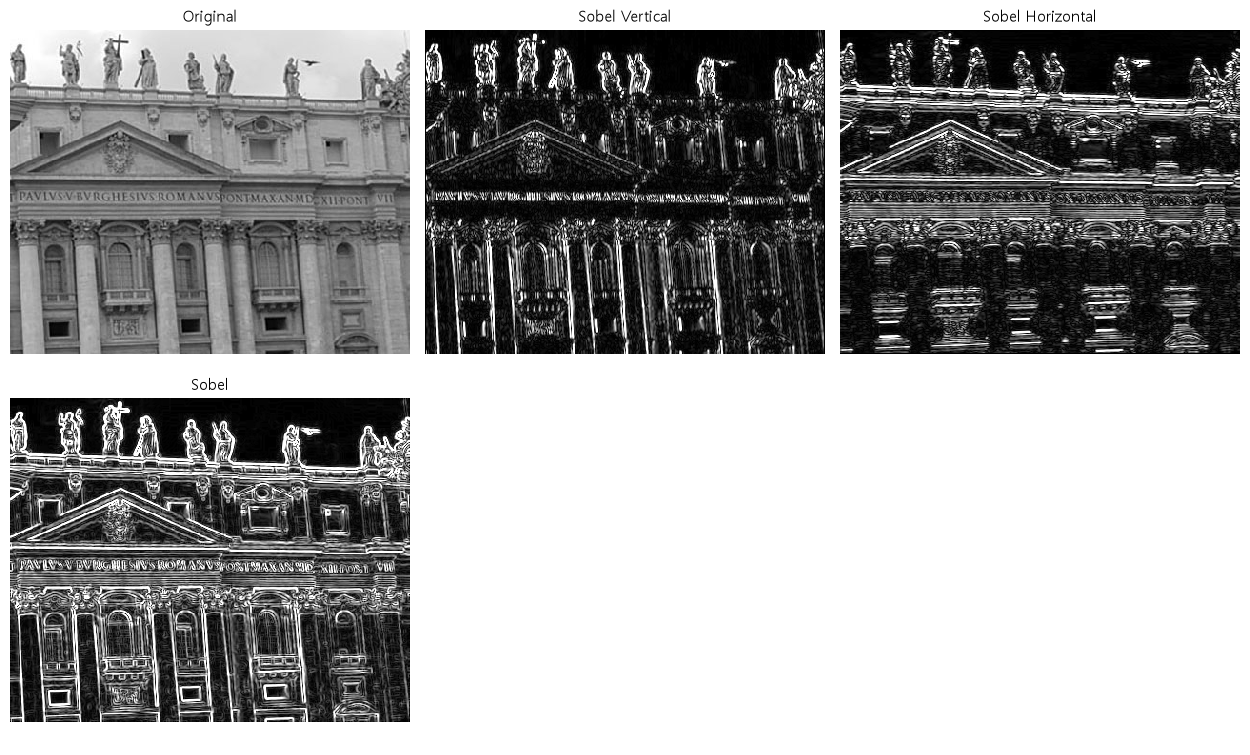

In [11]:
# Sobel 마스크
image = cv2.imread("../multi_info/images/edge.jpg", cv2.IMREAD_GRAYSCALE)
if image is None: raise Exception("영상 파일 읽기 오류")

v_mask = np.array([-1, 0, 1, -2, 0, 2, -1, 0, 1], np.float32).reshape(3,3)
h_mask = np.array([-1, -2, -1, 0, 0, 0, 1, 2, 1], np.float32).reshape(3,3)
sobel_v = cv2.filter2D(image, cv2.CV_32F, v_mask)
sobel_h = cv2.filter2D(image, cv2.CV_32F, h_mask)

sobel = cv2.magnitude(sobel_v, sobel_h)
sobel = np.clip(sobel, 0, 255).astype(np.uint8)
sobel_v_show = cv2.convertScaleAbs(sobel_v)
sobel_h_show = cv2.convertScaleAbs(sobel_h)

cv2.imshow("Original", image)
cv2.imshow("Sobel Vertical", sobel_v_show)
cv2.imshow("Sobel Horizontal", sobel_h_show)
cv2.imshow("Sobel", sobel)

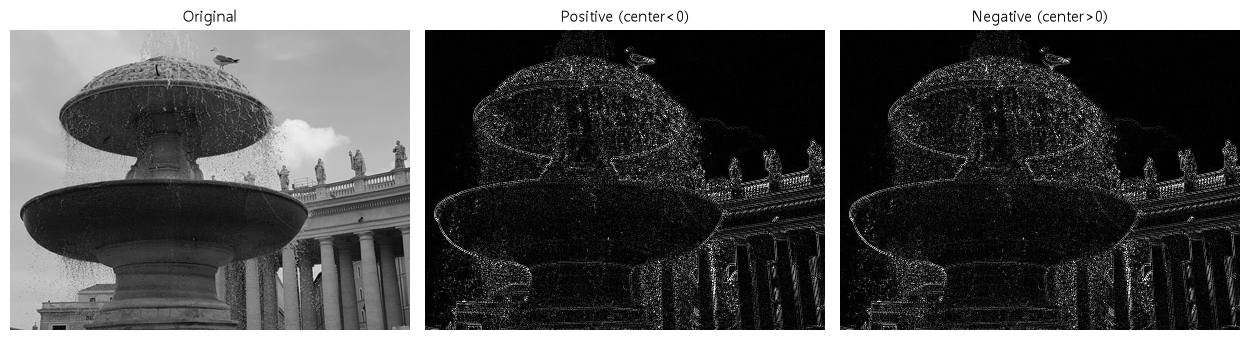

In [12]:
# laplacian 에지
image = cv2.imread("../multi_info/images/laplacian.jpg", cv2.IMREAD_GRAYSCALE)
if image is None: raise Exception("영상 파일 읽기 오류")

pos_m4 = np.array([[0, 1, 0],[1, -4, 1],[0, 1, 0]], np.float32).reshape(3,3)
neg_m4 = np.array([[0, -1, 0],[-1, 4, -1],[0, -1, 0]], np.float32).reshape(3,3)

pos_lap = cv2.filter2D(image, cv2.CV_32F, pos_m4)
neg_lap = cv2.filter2D(image, cv2.CV_32F, neg_m4)
pos_lap_show = cv2.convertScaleAbs(pos_lap)
neg_lap_show = cv2.convertScaleAbs(neg_lap)

cv2.imshow("Original", image)
cv2.imshow("Positive (center<0)", pos_lap_show)
cv2.imshow("Negative (center>0)", neg_lap_show)